# Lab 5: Neural Network for Handwritten Digit Recognition (MNIST)

A simple neural network that classifies 28 × 28 grayscale images of handwritten digits (0 to 9).

**Architecture:** 28 × 28 image → Flatten (784) → Dense 64 + ReLU → Dense 10 + Softmax → predicted digit

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

keras.utils.set_random_seed(42)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 1. Load the data

MNIST ships with Keras: 60,000 training images and 10,000 test images, each with its label.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print('Training images:', x_train.shape, '  labels:', y_train.shape)
print('Test images:    ', x_test.shape, '  labels:', y_test.shape)
print('Pixel range:', x_train.min(), 'to', x_train.max())

Training images: (60000, 28, 28)   labels: (60000,)
Test images:     (10000, 28, 28)   labels: (10000,)


Pixel range: 0 to 255


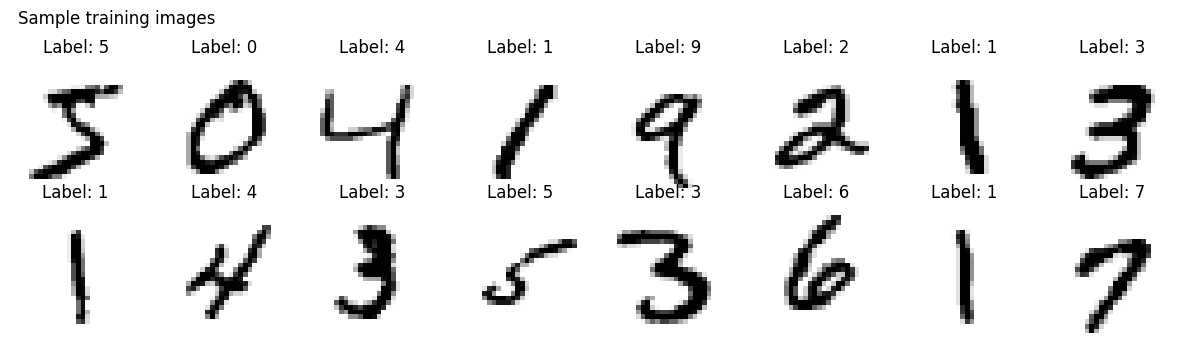

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
plt.suptitle('Sample training images', x=0.02, ha='left')
plt.tight_layout()
plt.show()

## 2. Tensors

A tensor is a multidimensional array; its **rank** is the number of axes.

In [4]:
scalar = tf.constant(5)
vector = tf.constant([5, 2, 8])
matrix = tf.constant(x_train[0])
batch = tf.constant(x_train[:32])

for name, t in [('Scalar', scalar), ('Vector', vector), ('Matrix (one image)', matrix), ('Image batch', batch)]:
    print(f'{name:20s} rank {tf.rank(t).numpy()}  shape {t.shape}')

Scalar               rank 0  shape ()
Vector               rank 1  shape (3,)
Matrix (one image)   rank 2  shape (28, 28)
Image batch          rank 3  shape (32, 28, 28)


NumPy arrays and tensors hold the same numbers and convert back and forth freely.

In [5]:
t = tf.convert_to_tensor(x_train[0], dtype=tf.float32)
back = t.numpy()
print(type(t).__name__, t.dtype, '->', type(back).__name__, back.dtype)
print('Values identical:', np.array_equal(back, x_train[0]))

EagerTensor <dtype: 'float32'> -> ndarray float32
Values identical: True


## 3. Prepare the data

- Scale pixels from 0–255 to 0–1 as floats, which helps training.
- One-hot encode labels so they match the 10 output units, e.g. 3 → `[0,0,0,1,0,0,0,0,0,0]`.

In [6]:
x_train_scaled = x_train.astype('float32') / 255
x_test_scaled = x_test.astype('float32') / 255

y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

print('Label', y_train[0], '->', y_train_onehot[0])

Label 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 4. Build the network

In [7]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(name='flatten'),
    layers.Dense(64, activation='relu', name='hidden'),
    layers.Dense(10, activation='softmax', name='output'),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

The parameter counts check out: the hidden layer has 784 × 64 weights + 64 biases = 50,240, and the output layer has 64 × 10 + 10 = 650.

## 5. Compile and train

- **Loss:** categorical cross-entropy, for a 10-class one-hot target
- **Optimiser:** Adam
- **Metric:** accuracy

Train for 10 epochs, holding back 33% of the training set for validation.

In [8]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(x_train_scaled, y_train_onehot, epochs=10, validation_split=0.33, verbose=2)

Epoch 1/10


1257/1257 - 2s - 2ms/step - accuracy: 0.8989 - loss: 0.3588 - val_accuracy: 0.9395 - val_loss: 0.2122


Epoch 2/10


1257/1257 - 2s - 1ms/step - accuracy: 0.9492 - loss: 0.1744 - val_accuracy: 0.9518 - val_loss: 0.1630


Epoch 3/10


1257/1257 - 2s - 1ms/step - accuracy: 0.9627 - loss: 0.1283 - val_accuracy: 0.9590 - val_loss: 0.1419


... (10 outputs left out)

Epoch 9/10


1257/1257 - 2s - 1ms/step - accuracy: 0.9904 - loss: 0.0386 - val_accuracy: 0.9614 - val_loss: 0.1363


Epoch 10/10


1257/1257 - 2s - 1ms/step - accuracy: 0.9925 - loss: 0.0320 - val_accuracy: 0.9632 - val_loss: 0.1353


## 6. Learning curves

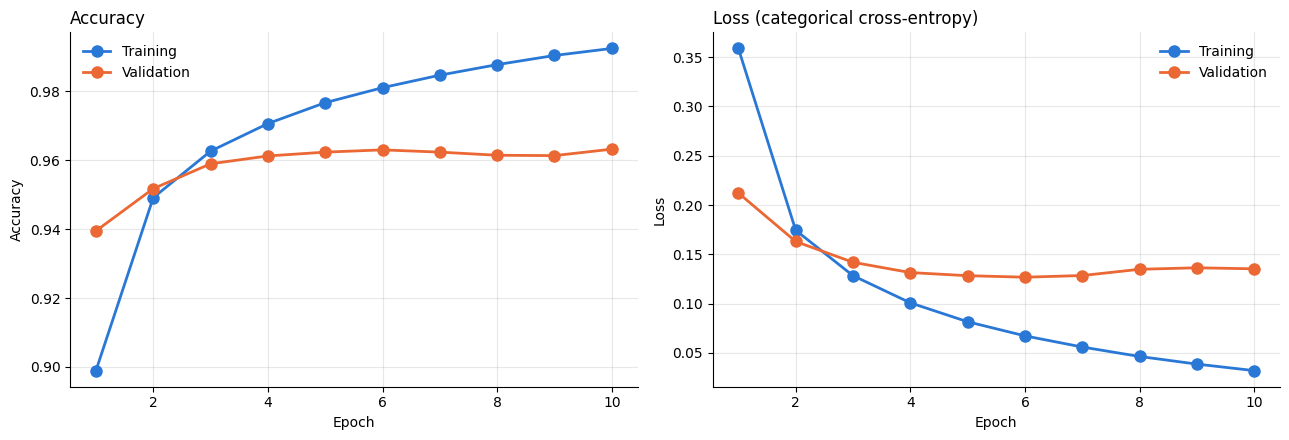

In [9]:
h = history.history
epochs = range(1, len(h['loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(epochs, h['accuracy'], color='#2a78d6', linewidth=2, marker='o', markersize=8, label='Training')
ax1.plot(epochs, h['val_accuracy'], color='#eb6834', linewidth=2, marker='o', markersize=8, label='Validation')
ax1.set_title('Accuracy', loc='left')
ax1.set_ylabel('Accuracy')
ax2.plot(epochs, h['loss'], color='#2a78d6', linewidth=2, marker='o', markersize=8, label='Training')
ax2.plot(epochs, h['val_loss'], color='#eb6834', linewidth=2, marker='o', markersize=8, label='Validation')
ax2.set_title('Loss (categorical cross-entropy)', loc='left')
ax2.set_ylabel('Loss')
for ax in (ax1, ax2):
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Training accuracy keeps climbing to about 99%, but validation accuracy levels off at about 96% after epoch 4, and validation loss starts creeping up after epoch 6. That widening gap is mild **overfitting**: the network is starting to memorise the training images. Stopping at around 5 or 6 epochs (or adding Dropout) would be a reasonable next step.

## 7. Evaluate on the test set

The test images were never seen during training or validation.

In [10]:
test_loss, test_acc = model.evaluate(x_test_scaled, y_test_onehot, verbose=0)
print(f'Test accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}')

Test accuracy: 0.9695   Test loss: 0.1148


## 8. Predictions

The network outputs 10 softmax probabilities; the predicted digit is the position of the largest (argmax).

In [11]:
probs = model.predict(x_test_scaled, verbose=0)
y_pred = probs.argmax(axis=1)

print('Softmax output for the first test image:')
print(np.round(probs[0], 3), ' sum =', probs[0].sum().round(3))
print('Predicted:', y_pred[0], '  True:', y_test[0])

Softmax output for the first test image:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]  sum = 1.0
Predicted: 7   True: 7


305 of 10000 test images misclassified


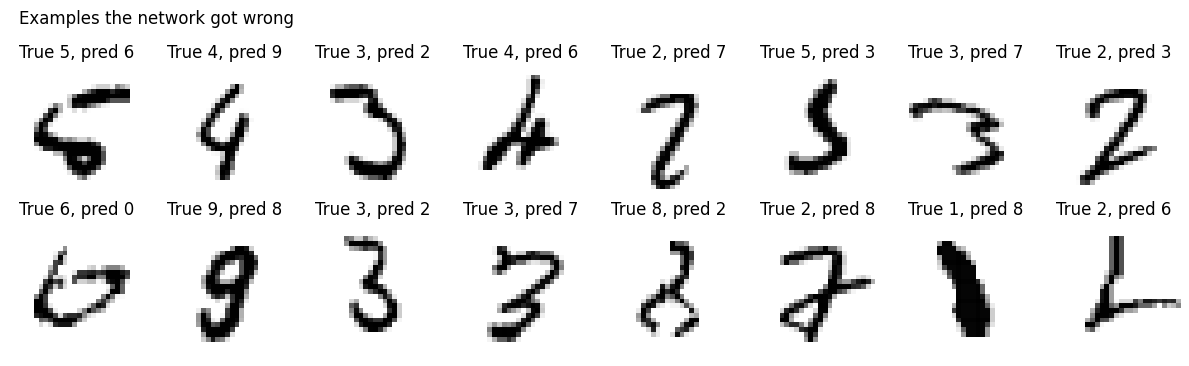

In [12]:
wrong = np.where(y_pred != y_test)[0]
print(f'{len(wrong)} of {len(y_test)} test images misclassified')

fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(x_test[i], cmap='gray_r')
    ax.set_title(f'True {y_test[i]}, pred {y_pred[i]}')
    ax.axis('off')
plt.suptitle('Examples the network got wrong', x=0.02, ha='left')
plt.tight_layout()
plt.show()

## 9. Confusion matrix

Rows are true digits, columns are predicted digits. The diagonal holds correct predictions.

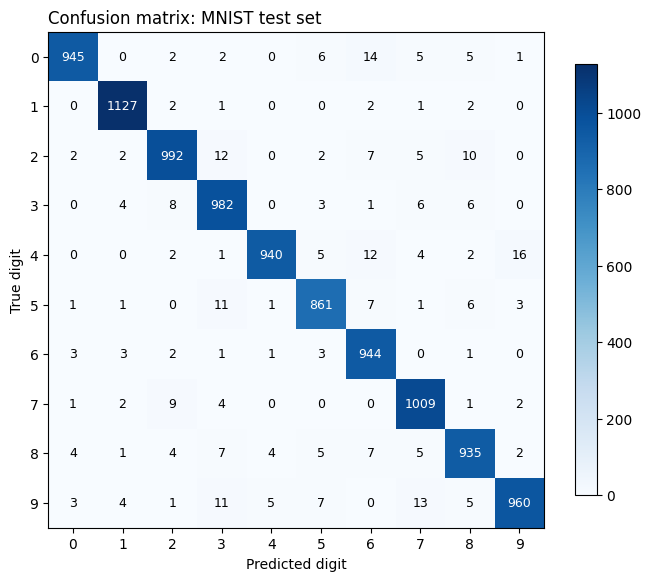

In [13]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel('Predicted digit')
ax.set_ylabel('True digit')
ax.set_title('Confusion matrix: MNIST test set', loc='left')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

In [14]:
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
print('Most common mistakes:')
for idx in np.argsort(off_diag, axis=None)[::-1][:5]:
    t, p = divmod(idx, 10)
    print(f'  true {t} predicted as {p}: {off_diag[t, p]} times')

per_class = cm.diagonal() / cm.sum(axis=1)
print('\nHardest digit:', per_class.argmin(), f'({per_class.min():.1%} correct)')
print('Easiest digit:', per_class.argmax(), f'({per_class.max():.1%} correct)')

Most common mistakes:
  true 4 predicted as 9: 16 times
  true 0 predicted as 6: 14 times
  true 9 predicted as 7: 13 times
  true 2 predicted as 3: 12 times
  true 4 predicted as 6: 12 times

Hardest digit: 9 (95.1% correct)
Easiest digit: 1 (99.3% correct)


## 10. Inside the hidden layer

The 64 hidden activations are the network's learned representation of each image. Reshaping them to 8 × 8 is only a convenient way to display 64 numbers; it is not a miniature digit.

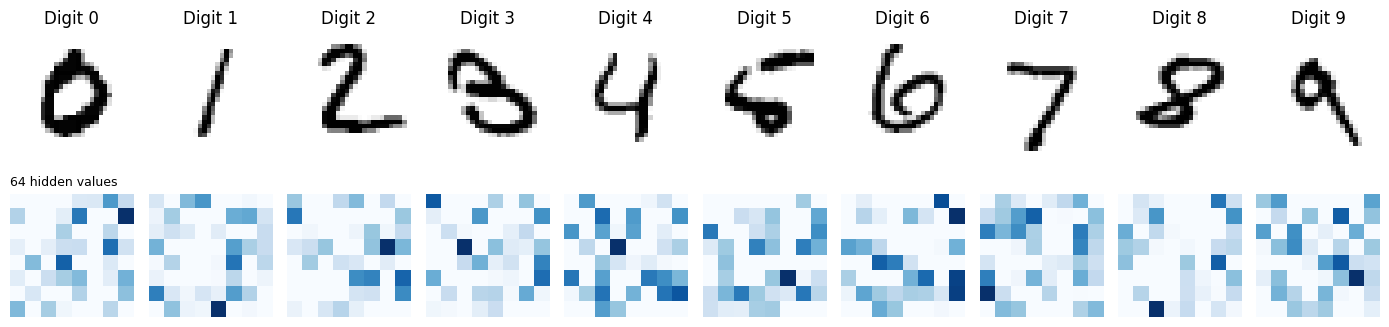

On average 46% of hidden units output exactly 0 (switched off by ReLU)


In [15]:
hidden_model = keras.Model(inputs=model.inputs, outputs=model.get_layer('hidden').output)
samples = [np.where(y_test == d)[0][0] for d in range(10)]
activations = hidden_model.predict(x_test_scaled[samples], verbose=0)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.6))
for k, i in enumerate(samples):
    axes[0, k].imshow(x_test[i], cmap='gray_r')
    axes[0, k].set_title(f'Digit {y_test[i]}')
    axes[1, k].imshow(activations[k].reshape(8, 8), cmap='Blues')
    axes[0, k].axis('off'); axes[1, k].axis('off')
axes[1, 0].set_title('64 hidden values', loc='left', fontsize=9)
plt.tight_layout()
plt.show()

print(f'On average {np.mean(activations == 0):.0%} of hidden units output exactly 0 (switched off by ReLU)')

Each digit switches on a different pattern of hidden units, and many units sit at zero because ReLU suppresses negative values. The output layer reads these patterns to pick the most likely digit.